In [1]:
!pip -q install pandas numpy matplotlib folium geopandas shapely

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from pathlib import Path
from IPython.display import display

In [4]:
from google.colab import files
uploaded = files.upload()  # pilih dataset_dummy_aset_gis.csv
csv_name = next((name for name in uploaded if name.lower().endswith('.csv')), None)
if csv_name is None:
    raise ValueError('Unggah file CSV terlebih dahulu.')
df = pd.read_csv(csv_name)
print('Ukuran data:', df.shape)
display(df.head())

Saving dataset_dummy_aset_gis.csv to dataset_dummy_aset_gis (1).csv
Ukuran data: (500, 11)


,asset_id,nama_aset,jenis_aset,latitude,longitude,tahun_pemasangan,usia_aset_tahun,status_keluhan,status_kondisi,tanggal_laporan,biaya_estimasi_rp
0,AST-0001,Pohon 001,Pohon,-3.864055,102.257754,2021,5,Tidak Ada,Baik,2025-08-07,0
1,AST-0002,Lampu Jalan 002,Lampu Jalan,-3.792356,102.181337,2002,24,Kerusakan Ringan,Perlu Pemeriksaan,2025-03-10,11404134
2,AST-0003,Jalan 003,Jalan,-3.785861,102.247743,1999,27,Tidak Ada,Baik,2026-09-09,0
3,AST-0004,Taman 004,Taman,-3.761242,102.254030,1999,27,Kerusakan Ringan,Perlu Pemeriksaan,2026-09-22,3369911
4,AST-0005,Taman 005,Taman,-3.851769,102.174129,2022,4,Kerusakan Berat,Prioritas Tinggi,2025-03-14,2276151


In [5]:
print('Kolom:', df.columns.tolist())
print('Nilai kosong per kolom:')
display(df.isna().sum().to_frame('jumlah_kosong'))
print('Duplikasi asset_id:', df['asset_id'].duplicated().sum())
print('Rentang koordinat dummy:')
print('Latitude:', df.latitude.min(), 'sampai', df.latitude.max())
print('Longitude:', df.longitude.min(), 'sampai', df.longitude.max())

Kolom: ['asset_id', 'nama_aset', 'jenis_aset', 'latitude', 'longitude', 'tahun_pemasangan', 'usia_aset_tahun', 'status_keluhan', 'status_kondisi', 'tanggal_laporan', 'biaya_estimasi_rp']
Nilai kosong per kolom:


,jumlah_kosong
asset_id,0
nama_aset,0
jenis_aset,0
latitude,0
longitude,0
tahun_pemasangan,0
usia_aset_tahun,0
status_keluhan,0
status_kondisi,0
tanggal_laporan,0


Duplikasi asset_id: 0
Rentang koordinat dummy:
Latitude: -3.940014 sampai -3.65437
Longitude: 102.11206 sampai 102.431676


In [6]:
print('Jumlah aset per jenis:')
display(df['jenis_aset'].value_counts().to_frame('jumlah_aset'))
print('Kondisi aset:')
display(df['status_kondisi'].value_counts().to_frame('jumlah'))

Jumlah aset per jenis:


,jumlah_aset
jenis_aset,
Pohon,119
Jalan,96
Taman,78
Lampu Jalan,68
Drainase,58
Lapangan Bermain,47
Perpustakaan,34


Kondisi aset:


,jumlah
status_kondisi,
Baik,211
Perlu Pemeriksaan,140
Perlu Perbaikan,97
Prioritas Tinggi,52


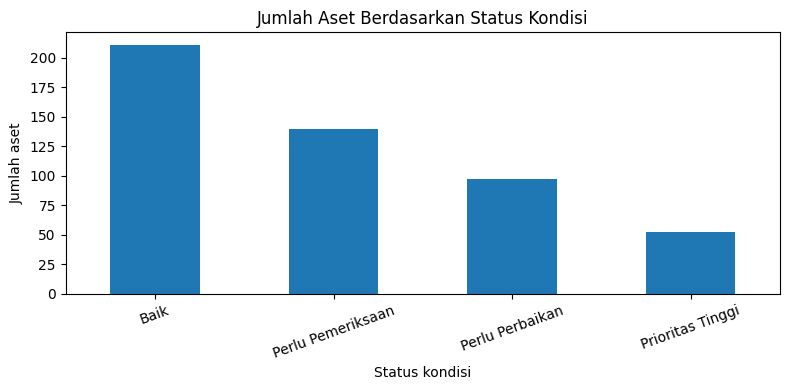

In [7]:
ax = df['status_kondisi'].value_counts().plot(kind='bar', figsize=(8,4))
ax.set_title('Jumlah Aset Berdasarkan Status Kondisi')
ax.set_xlabel('Status kondisi'); ax.set_ylabel('Jumlah aset')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

In [8]:
# Titik peta ini sintetis dan hanya untuk demonstrasi
center = [df['latitude'].mean(), df['longitude'].mean()]
map_aset = folium.Map(location=center, zoom_start=12, tiles='OpenStreetMap')
warna = {'Baik':'green', 'Perlu Pemeriksaan':'orange', 'Perlu Perbaikan':'red', 'Prioritas Tinggi':'darkred'}
for _, row in df.iterrows():
    popup = (f"<b>{row['nama_aset']}</b><br>Jenis: {row['jenis_aset']}<br>"
             f"Kondisi: {row['status_kondisi']}<br>ID: {row['asset_id']}")
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']], radius=5,
        color=warna.get(row['status_kondisi'], 'blue'), fill=True,
        fill_opacity=0.75, popup=folium.Popup(popup, max_width=250)
    ).add_to(map_aset)
map_aset

In [9]:
prioritas_order = {'Prioritas Tinggi': 0, 'Perlu Perbaikan': 1, 'Perlu Pemeriksaan': 2, 'Baik': 3}
df['urutan_prioritas'] = df['status_kondisi'].map(prioritas_order)
daftar_prioritas = df.sort_values(['urutan_prioritas','biaya_estimasi_rp'], ascending=[True, False])
display(daftar_prioritas[['asset_id','nama_aset','jenis_aset','status_kondisi','biaya_estimasi_rp']].head(20))

,asset_id,nama_aset,jenis_aset,status_kondisi,biaya_estimasi_rp
317,AST-0318,Jalan 318,Jalan,Prioritas Tinggi,11387532
293,AST-0294,Jalan 294,Jalan,Prioritas Tinggi,11251132
39,AST-0040,Taman 040,Taman,Prioritas Tinggi,11213649
29,AST-0030,Taman 030,Taman,Prioritas Tinggi,11080959
374,AST-0375,Lapangan Bermain 375,Lapangan Bermain,Prioritas Tinggi,11070846
335,AST-0336,Jalan 336,Jalan,Prioritas Tinggi,11030025
305,AST-0306,Taman 306,Taman,Prioritas Tinggi,10979931
404,AST-0405,Pohon 405,Pohon,Prioritas Tinggi,10133033
201,AST-0202,Lampu Jalan 202,Lampu Jalan,Prioritas Tinggi,10081885
30,AST-0031,Pohon 031,Pohon,Prioritas Tinggi,10023107


In [10]:
ringkasan_biaya = df.groupby('status_kondisi', as_index=False).agg(
    jumlah_aset=('asset_id','count'), total_estimasi_rp=('biaya_estimasi_rp','sum')
)
display(ringkasan_biaya)
print('Total estimasi biaya dummy: Rp', f"{df['biaya_estimasi_rp'].sum():,.0f}")

,status_kondisi,jumlah_aset,total_estimasi_rp
0,Baik,211,0
1,Perlu Pemeriksaan,140,843728280
2,Perlu Perbaikan,97,574109945
3,Prioritas Tinggi,52,313014993


Total estimasi biaya dummy: Rp 1,730,853,218


In [11]:
# Membuat GeoJSON dengan struktur longitude-latitude sesuai standar GeoJSON
features = []
for _, row in df.iterrows():
    props = row.drop(labels=['latitude','longitude']).to_dict()
    features.append({
        'type': 'Feature',
        'geometry': {'type':'Point', 'coordinates':[float(row['longitude']), float(row['latitude'])]},
        'properties': {k: (None if pd.isna(v) else (v.item() if hasattr(v,'item') else v)) for k,v in props.items()}
    })
geojson = {'type':'FeatureCollection','features':features}
import json
with open('aset_kota_dummy.geojson','w',encoding='utf-8') as f:
    json.dump(geojson,f,ensure_ascii=False,indent=2,default=str)
print('GeoJSON tersimpan:', Path('aset_kota_dummy.geojson').resolve())

GeoJSON tersimpan: /content/aset_kota_dummy.geojson


In [12]:
df.to_csv('hasil_aset_gis_dummy.csv', index=False)
from google.colab import files
files.download('hasil_aset_gis_dummy.csv')
files.download('aset_kota_dummy.geojson')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>